# Performing data exploration, transformation and visualization

## Importing necessary libraries and constant strings.

In [ ]:
from sqlalchemy import create_engine
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

HOST = ""
USER = ""
PASSWORD = ""
PORT = 3306
DATABASE = "project_purchase_pattern_analysis"
TABLE = "mytable"

## Connection to the database

In [118]:
connection_url = f"mysql+pymysql://{USER}:{PASSWORD}@{HOST}:{PORT}/{DATABASE}"

engine = create_engine(connection_url)

## Reading the data from database using pandas.

In [ ]:


data = pd.read_sql(f"select * from {TABLE}", engine)

data

,BillNo,Itemname,Quantity,Present_Date,Price,CustomerID,Country
0,536365,WHITE HANGING HEART T-LIGHT HOLDER,6,01-12-2010 08:26,2.55,17850,United Kingdom
1,536365,WHITE METAL LANTERN,6,01-12-2010 08:26,3.39,17850,United Kingdom
2,536365,CREAM CUPID HEARTS COAT HANGER,8,01-12-2010 08:26,2.75,17850,United Kingdom
3,536365,KNITTED UNION FLAG HOT WATER BOTTLE,6,01-12-2010 08:26,3.39,17850,United Kingdom
4,536365,RED WOOLLY HOTTIE WHITE HEART.,6,01-12-2010 08:26,3.39,17850,United Kingdom
...,...,...,...,...,...,...,...
522059,581587,PACK OF 20 SPACEBOY NAPKINS,12,09-12-2011 12:50,0.85,12680,France
522060,581587,CHILDREN'S APRON DOLLY GIRL,6,09-12-2011 12:50,2.10,12680,France
522061,581587,CHILDRENS CUTLERY DOLLY GIRL,4,09-12-2011 12:50,4.15,12680,France
522062,581587,CHILDRENS CUTLERY CIRCUS PARADE,4,09-12-2011 12:50,4.15,12680,France


In [120]:
data.shape

(522064, 7)

In [121]:
data.head()

,BillNo,Itemname,Quantity,Present_Date,Price,CustomerID,Country
0,536365,WHITE HANGING HEART T-LIGHT HOLDER,6,01-12-2010 08:26,2.55,17850,United Kingdom
1,536365,WHITE METAL LANTERN,6,01-12-2010 08:26,3.39,17850,United Kingdom
2,536365,CREAM CUPID HEARTS COAT HANGER,8,01-12-2010 08:26,2.75,17850,United Kingdom
3,536365,KNITTED UNION FLAG HOT WATER BOTTLE,6,01-12-2010 08:26,3.39,17850,United Kingdom
4,536365,RED WOOLLY HOTTIE WHITE HEART.,6,01-12-2010 08:26,3.39,17850,United Kingdom


In [122]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 522064 entries, 0 to 522063
Data columns (total 7 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   BillNo        522064 non-null  str    
 1   Itemname      522064 non-null  str    
 2   Quantity      522064 non-null  int64  
 3   Present_Date  522064 non-null  str    
 4   Price         522064 non-null  float64
 5   CustomerID    522064 non-null  str    
 6   Country       522064 non-null  str    
dtypes: float64(1), int64(1), str(5)
memory usage: 27.9 MB


## Standardizing the dates column

In [123]:
data["Present_Date"] = pd.to_datetime(data["Present_Date"], format="%d-%m-%Y %H:%M")

In [124]:
data.describe()

,Quantity,Present_Date,Price
count,522064.000000,522064,522064.000000
mean,10.090435,2011-07-04 12:51:20.777107,3.826801
min,-9600.000000,2010-12-01 08:26:00,-11062.060000
25%,1.000000,2011-03-28 10:15:00,1.250000
50%,3.000000,2011-07-20 08:59:00,2.080000
75%,10.000000,2011-10-19 14:12:00,4.130000
max,80995.000000,2011-12-09 12:50:00,13541.330000
std,161.110525,NaN,41.900599


## Calculating revenue from quantity and price.

In [ ]:
data["Revenue"] = data["Quantity"] * data["Price"]

In [126]:
for col in ["Quantity", "Price"]:
    
     print(col)
     print(data[col].mean())
     print(data[col].median())
     print(data[col].mode())

Quantity
10.090435272303779
3.0
0    1
Name: Quantity, dtype: int64
Price
3.8268013768426856
2.08
0    1.25
Name: Price, dtype: float64


## Calculating basket size

In [ ]:
basket_size = data.groupby("BillNo")["Itemname"].nunique()

In [128]:
print(basket_size.describe())
print(data["Itemname"].value_counts().head(10))
print(data["Country"].value_counts().head(5))

count    21663.000000
mean        23.601533
std         45.554770
min          1.000000
25%          4.000000
50%         13.000000
75%         26.000000
max       1108.000000
Name: Itemname, dtype: float64
Itemname
WHITE HANGING HEART T-LIGHT HOLDER    2269
JUMBO BAG RED RETROSPOT               2087
REGENCY CAKESTAND 3 TIER              1930
PARTY BUNTING                         1677
LUNCH BAG RED RETROSPOT               1570
ASSORTED COLOUR BIRD ORNAMENT         1465
                                      1455
SET OF 3 CAKE TINS PANTRY DESIGN      1360
PACK OF 72 RETROSPOT CAKE CASES       1328
LUNCH BAG  BLACK SKULL.               1315
Name: count, dtype: int64
Country
United Kingdom    487622
Germany             9042
France              8408
Spain               2485
Netherlands         2363
Name: count, dtype: int64


## Hist plot for quantity per row.

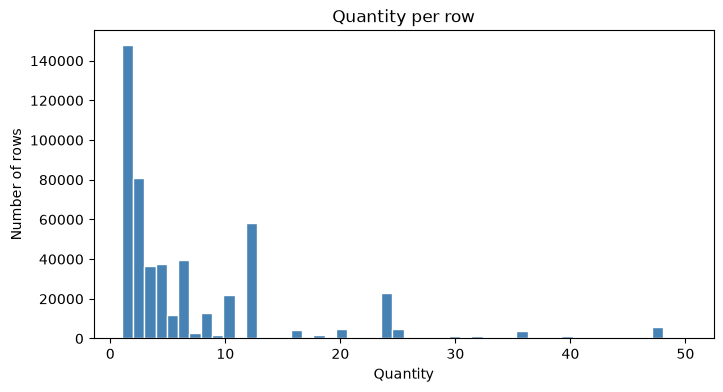

In [129]:
plt.figure(figsize=(8, 4))
plt.hist(data[data["Quantity"].between(1, 50)]["Quantity"], bins=50, color="steelblue", edgecolor="white")
plt.title("Quantity per row")
plt.xlabel("Quantity")
plt.ylabel("Number of rows")
plt.show()

## Boxplot for price capped at 50

C:\Users\shalo\AppData\Local\Temp\ipykernel_19564\2993314888.py:2: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(data["Price"].clip(upper=50), vert=False)


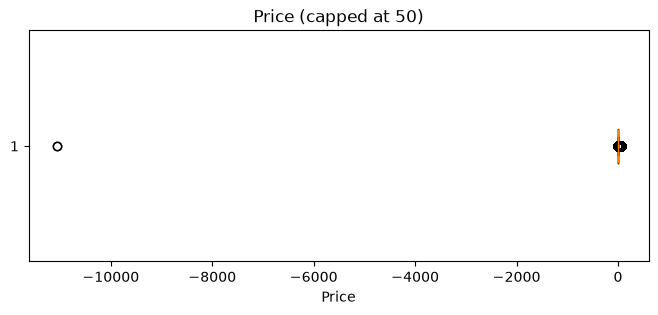

In [130]:
plt.figure(figsize=(8, 3))
plt.boxplot(data["Price"].clip(upper=50), vert=False)
plt.title("Price (capped at 50)")
plt.xlabel("Price")
plt.show()

## Hist plot for products per basket

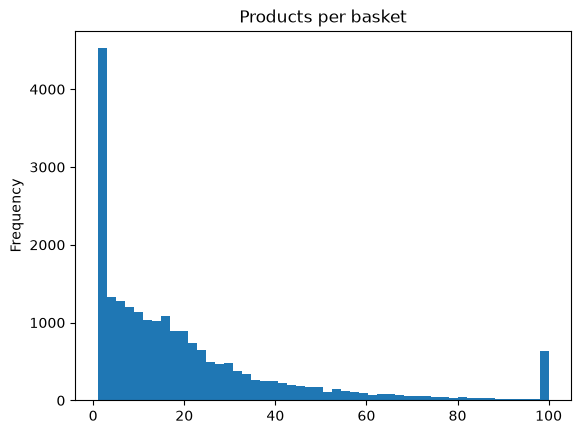

In [131]:
basket_size.clip(upper=100).plot(kind="hist", bins=50, title="Products per basket"); 
plt.show()

## Plot for monthly revenue

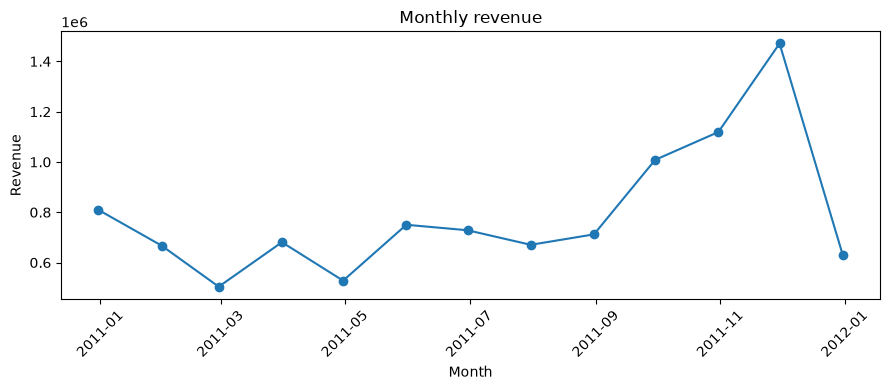

In [132]:
monthly = data.set_index("Present_Date")["Revenue"].resample("ME").sum()

plt.figure(figsize=(9, 4))
plt.plot(monthly.index, monthly.values, marker="o")
plt.title("Monthly revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Plot for top 10 products per rows.

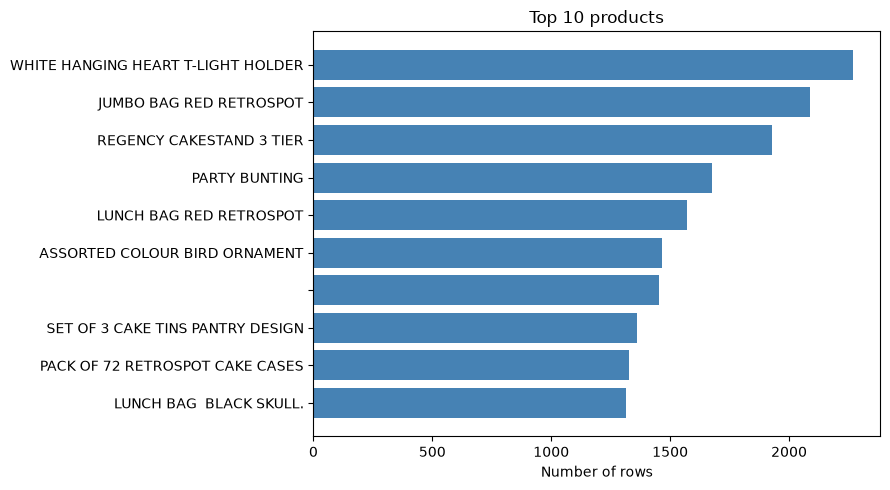

In [133]:
top10 = data["Itemname"].value_counts().head(10).sort_values()

plt.figure(figsize=(9, 5))
plt.barh(top10.index, top10.values, color="steelblue")
plt.title("Top 10 products")
plt.xlabel("Number of rows")
plt.tight_layout()
plt.show()

## Plot for rows per hour per day.

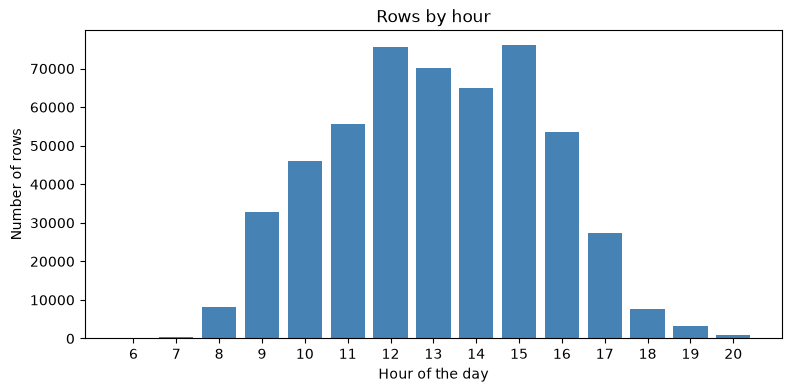

In [134]:
by_hour = data["Present_Date"].dt.hour.value_counts().sort_index()

plt.figure(figsize=(9, 4))
plt.bar(by_hour.index, by_hour.values, color="steelblue")
plt.title("Rows by hour")
plt.xlabel("Hour of the day")
plt.ylabel("Number of rows")
plt.xticks(by_hour.index)
plt.show()

## Calculating all null values from the table

In [135]:
print(data.isnull().sum())

BillNo          0
Itemname        0
Quantity        0
Present_Date    0
Price           0
CustomerID      0
Country         0
Revenue         0
dtype: int64


## Calculating total duplicate rows from data

In [136]:
print("Duplicate row:", data.duplicated().sum())

Duplicate row: 5286


## Getting billNO which starts with C

In [137]:
print("Return (BillNo starts with C):",
data["BillNo"].astype(str).str.startswith("C").sum())

Return (BillNo starts with C): 0


## Checking if how many negative values in quantity and price

In [138]:
print("Negative quantity:", (data["Quantity"] < 0).sum())
print("Zero or negative price:", (data["Price"] <= 0).sum())

Negative quantity: 1336
Zero or negative price: 2513


## Calculating outliers for quantity and price

In [139]:
for col in ["Quantity", "Price"]:
    q1 = data[col].quantile(0.25)
    q3 = data[col].quantile(0.75)
    low = q1 - 1.5 * (q3 - q1)
    high = q3 + 1.5 * (q3 - q1)
print(col, "normal range:", low, "to", high,
    "| outliers:", ((data[col] < low) | (data[col] > high)).sum())

Price normal range: -3.0700000000000003 to 8.45 | outliers: 36941


## getting item names according to business rule and uniques.

In [140]:
print(data[data["Itemname"].astype(str).str.upper().str.contains("POSTAGE|MANUAL|DISCOUNT|BANK CHARGES|CARRIAGE|AMAZON FEE")]
      ["Itemname"].unique())

<StringArray>
[                     'POSTAGE',               'DOTCOM POSTAGE',
                       'Manual',                 'Bank Charges',
                   'AMAZON FEE',                     'CARRIAGE',
 'BLACK BAROQUE CARRIAGE CLOCK',      'FRENCH CARRIAGE LANTERN',
            'Next Day Carriage']
Length: 9, dtype: str


# week 2 data transformation

## Function to get rows as required.

In [141]:
log = []

def record(step, before, after):
    log.append({"step": step, 
    "rows_before": before, 
    "rows_after": after,
    "rows_removed": before - after})

## Copied data into new variable to perform transformations.

In [142]:
clean = data.copy()

## Performing Transformations.

In [ ]:
n = len(clean)                                   

# striped bill no from white spaces.
clean["BillNo"] = clean["BillNo"].astype(str).str.strip()

# striping and changing to upper case.
clean["Itemname"] = clean["Itemname"].astype(str).str.strip().str.upper()

# replacing empty string with NAN and string "NAN with np.nan" and "None" with np.nan
clean = clean.replace({"": np.nan, "NAN": np.nan, "NONE": np.nan})

# removing null where billno and itemname
clean = clean.dropna(subset=["BillNo", "Itemname"])

record("Remove empty BillNo/Itemname", n, len(clean))

## Deleting duplicates from data

In [144]:
n = len(clean)
clean = clean.drop_duplicates()
record("Remove duplicates", n, len(clean))

## Getting all billno which does not start with C and values greater than zero

In [145]:
n = len(clean)
clean = clean[~clean["BillNo"].str.startswith("C")]
clean = clean[(clean["Quantity"] > 0) & (clean["Price"] > 0)]
record("Remove returns, zero or negative Quantity/Price", n, len(clean))

## Getting all itemnames except the condition

In [146]:
n = len(clean)
fees = "POSTAGE|MANUAL|DISCOUNT|BANK CHARGES|CARRIAGE|AMAZON FEE|CRUK COMMISSION|ADJUST"
clean = clean[~clean["Itemname"].str.contains(fees, regex=True)]
record("Remove fee rows", n, len(clean))

## removing outliers from quantity and price.

In [147]:
n = len(clean)
clean = clean[(clean["Quantity"] <= clean["Quantity"].quantile(0.999)) & (clean["Price"] <= clean["Price"].quantile(0.999))]
record("Remove outliers", n, len(clean))

## getting all unique billNO per ItemName

In [148]:
n = len(clean)
item_baskets = clean.groupby("Itemname")["BillNo"].nunique()
clean = clean[clean["Itemname"].isin(item_baskets[item_baskets >= 30].index)]
record("Remove rare products (< 30 baskets)", n, len(clean))

## Getting all itemnames unique per BillNo.

In [149]:
n = len(clean)
basket_items_count = clean.groupby("BillNo")["Itemname"].nunique()
clean = clean[clean["BillNo"].isin(basket_items_count[basket_items_count >= 2].index)]
record("Remove 1-product baskets", n, len(clean))

## reseting indexes.

In [150]:
clean = clean.reset_index(drop=True)
print(pd.DataFrame(log))

                                              step  rows_before  rows_after  \
0                     Remove empty BillNo/Itemname       522064      520609   
1                                Remove duplicates       520609      515323   
2  Remove returns, zero or negative Quantity/Price       515323      514270   
3                                  Remove fee rows       514270      511970   
4                                  Remove outliers       511970      510953   
5              Remove rare products (< 30 baskets)       510953      496141   
6                         Remove 1-product baskets       496141      494747   

   rows_removed  
0          1455  
1          5286  
2          1053  
3          2300  
4          1017  
5         14812  
6          1394  


In [151]:
basket = (clean.groupby(["BillNo", "Itemname"])["Quantity"].sum().unstack(fill_value=0) > 0)
print(basket.shape)

(17750, 2559)


## saving the cleaned data to csv.

In [152]:
clean.to_csv("cleaned_transactions.csv", index=False)
basket.to_csv("basket_matrix.csv")
pd.DataFrame(log).to_csv("cleaning_log.csv", index=False)

## Getting top 15 products ber basket

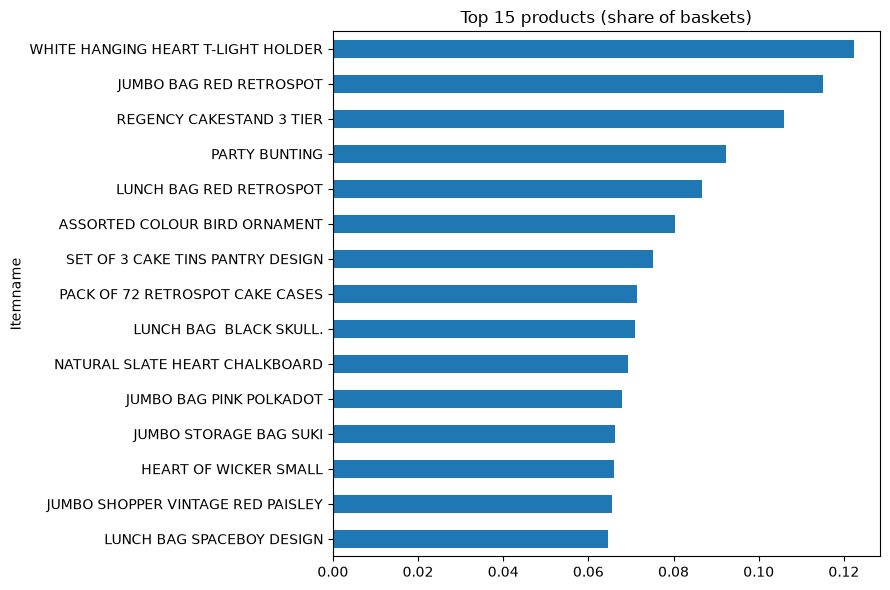

In [153]:
support_single = basket.mean().sort_values(ascending=False)
support_single.head(15).sort_values().plot(kind="barh", figsize=(9,6), title="Top 15 products (share of baskets)")
plt.tight_layout(); plt.show()

## Plotting top 15 products which brought together.

Itemname                            WHITE HANGING HEART T-LIGHT HOLDER  \
Itemname                                                                 
WHITE HANGING HEART T-LIGHT HOLDER                                2172   
JUMBO BAG RED RETROSPOT                                            439   
REGENCY CAKESTAND 3 TIER                                           343   
PARTY BUNTING                                                      382   
LUNCH BAG RED RETROSPOT                                            326   
ASSORTED COLOUR BIRD ORNAMENT                                      312   
SET OF 3 CAKE TINS PANTRY DESIGN                                   314   
PACK OF 72 RETROSPOT CAKE CASES                                    260   
LUNCH BAG  BLACK SKULL.                                            262   
NATURAL SLATE HEART CHALKBOARD                                     411   
JUMBO BAG PINK POLKADOT                                            255   
JUMBO STORAGE BAG SUKI                

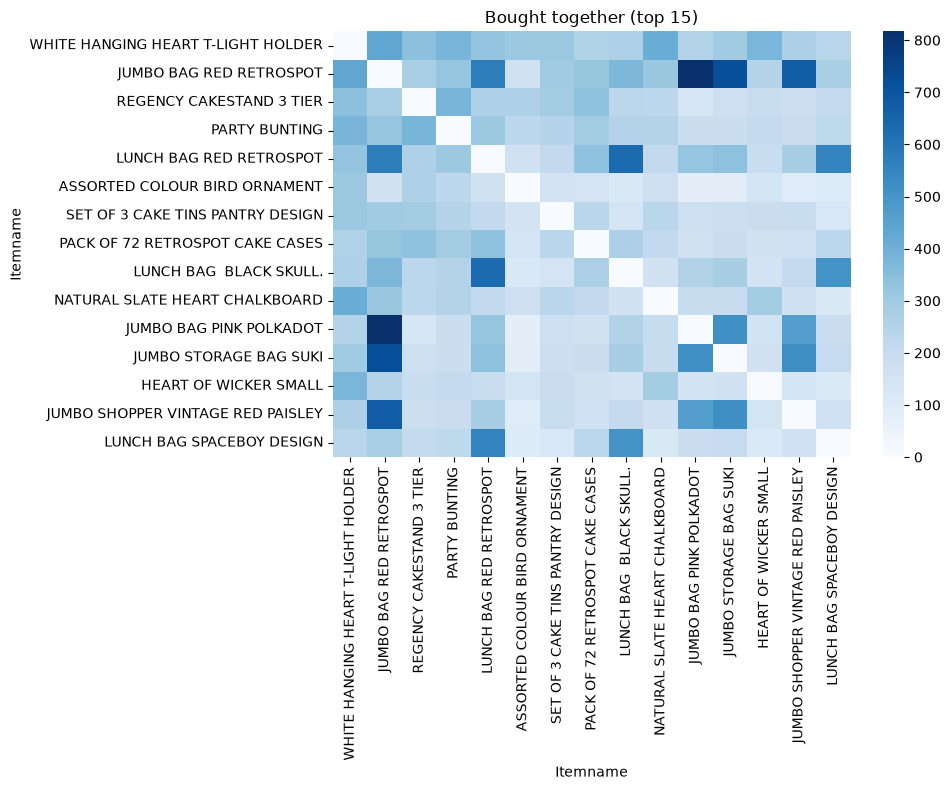

In [ ]:
top_items = support_single.head(15).index
b = basket[top_items].astype(int)
co = b.T.dot(b)
# print(co)
co = co.mask(np.eye(len(co), dtype=bool), 0) 
plt.figure(figsize=(10,8))
sns.heatmap(co, cmap="Blues"); 
plt.title("Bought together (top 15)")
plt.tight_layout(); 
plt.show()

## Ploting monthly baskets.

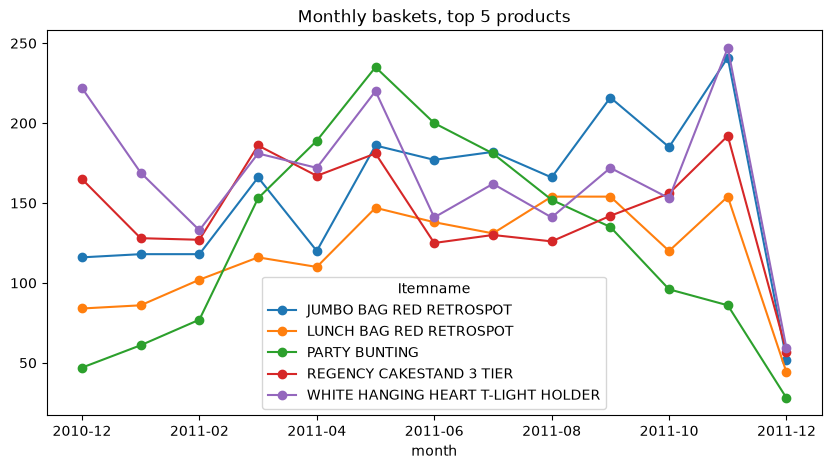

In [155]:
top5 = support_single.head(5).index
trend = (clean[clean["Itemname"].isin(top5)].assign(month=lambda d: 
                                                    d["Present_Date"].dt.to_period("M").astype(str)).groupby(["month", "Itemname"])["BillNo"].nunique().unstack(fill_value=0))
trend.plot(figsize=(10,5), marker="o", title="Monthly baskets, top 5 products"); 
plt.show()

## Performing apriori analysis

In [156]:
from mlxtend.frequent_patterns import apriori, association_rules
frequent = apriori(basket, min_support=0.015, use_colnames=True, max_len=3, low_memory=True)
print(len(frequent), "frequent sets")
print(frequent.sort_values("support", ascending=False).head(10))

890 frequent sets
      support                                         itemsets
507  0.122366  frozenset({WHITE HANGING HEART T-LIGHT HOLDER})
211  0.115099             frozenset({JUMBO BAG RED RETROSPOT})
359  0.106028            frozenset({REGENCY CAKESTAND 3 TIER})
292  0.092394                       frozenset({PARTY BUNTING})
246  0.086761             frozenset({LUNCH BAG RED RETROSPOT})
29   0.080338       frozenset({ASSORTED COLOUR BIRD ORNAMENT})
409  0.075268    frozenset({SET OF 3 CAKE TINS PANTRY DESIGN})
280  0.071493     frozenset({PACK OF 72 RETROSPOT CAKE CASES})
238  0.070873             frozenset({LUNCH BAG  BLACK SKULL.})
263  0.069296      frozenset({NATURAL SLATE HEART CHALKBOARD})


## Getting association rules.

In [157]:
rules = association_rules(frequent, metric="lift", min_threshold=1.0)
rules["antecedents"] = rules["antecedents"].apply(lambda s: ","
 .join(sorted(s)))
rules["consequents"] = rules["consequents"].apply(lambda s: ","
 .join(sorted(s)))
print(rules[["antecedents", "consequents", "support", "consequents", "lift"]].head(15))

                           antecedents                         consequents  \
0   PACK OF 60 PINK PAISLEY CAKE CASES         60 TEATIME FAIRY CAKE CASES   
1          60 TEATIME FAIRY CAKE CASES  PACK OF 60 PINK PAISLEY CAKE CASES   
2      PACK OF 72 RETROSPOT CAKE CASES         60 TEATIME FAIRY CAKE CASES   
3          60 TEATIME FAIRY CAKE CASES     PACK OF 72 RETROSPOT CAKE CASES   
4      PACK OF 72 RETROSPOT CAKE CASES      72 SWEETHEART FAIRY CAKE CASES   
5       72 SWEETHEART FAIRY CAKE CASES     PACK OF 72 RETROSPOT CAKE CASES   
6           ALARM CLOCK BAKELIKE GREEN      ALARM CLOCK BAKELIKE CHOCOLATE   
7       ALARM CLOCK BAKELIKE CHOCOLATE          ALARM CLOCK BAKELIKE GREEN   
8             ALARM CLOCK BAKELIKE RED      ALARM CLOCK BAKELIKE CHOCOLATE   
9       ALARM CLOCK BAKELIKE CHOCOLATE            ALARM CLOCK BAKELIKE RED   
10          ALARM CLOCK BAKELIKE GREEN          ALARM CLOCK BAKELIKE IVORY   
11          ALARM CLOCK BAKELIKE IVORY          ALARM CLOCK BAKE

## Saving apriori rules to csv

In [158]:
rules[["antecedents", "consequents", "support", "consequents", "lift"]].to_csv("apriori_rules.csv", index=False)

## Scatter Plot for association rules.

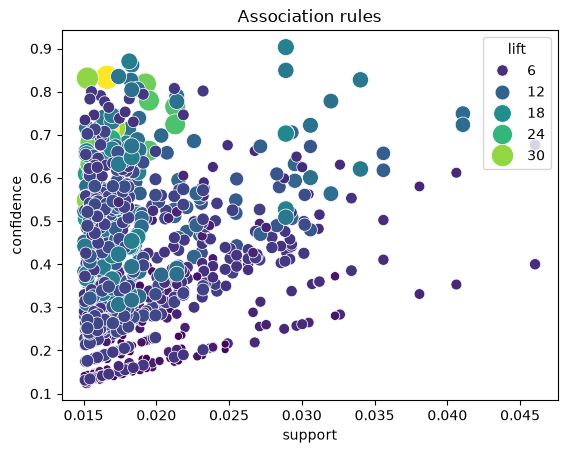

In [159]:
sns.scatterplot(data=rules, x="support", y="confidence", size="lift",
hue="lift", palette="viridis", sizes=(30,300))
plt.title("Association rules")
plt.show()

## bar plot for top 10 rules.

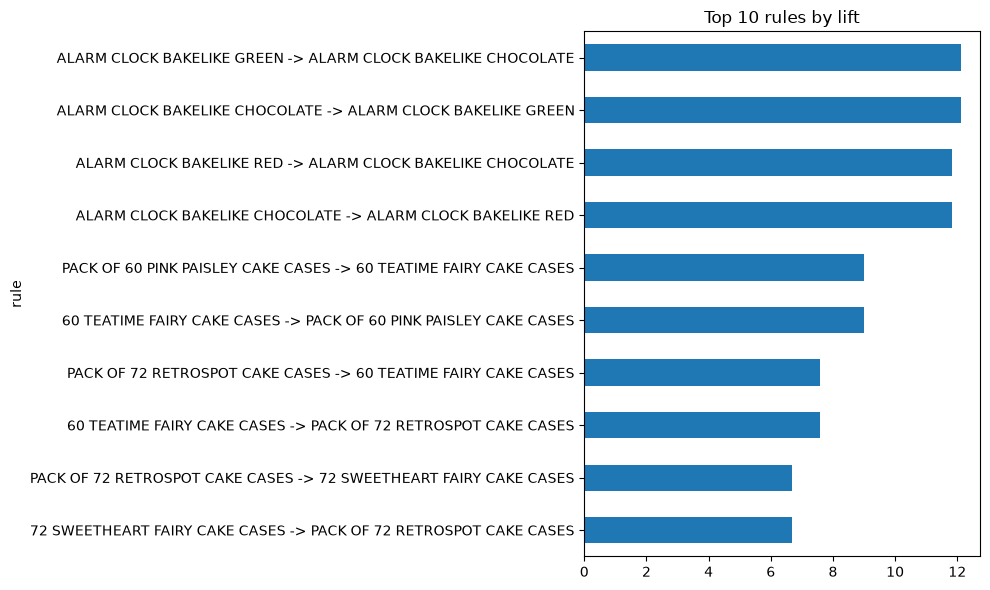

In [160]:
top = rules.head(10).copy()
top["rule"] = top["antecedents"] + " -> " + top["consequents"]
top.sort_values("lift").plot(kind="barh", x="rule", y="lift", figsize=(10,6), 
                             legend=False, title="Top 10 rules by lift")
plt.tight_layout()
plt.show()

## HeatMap for lift between products.

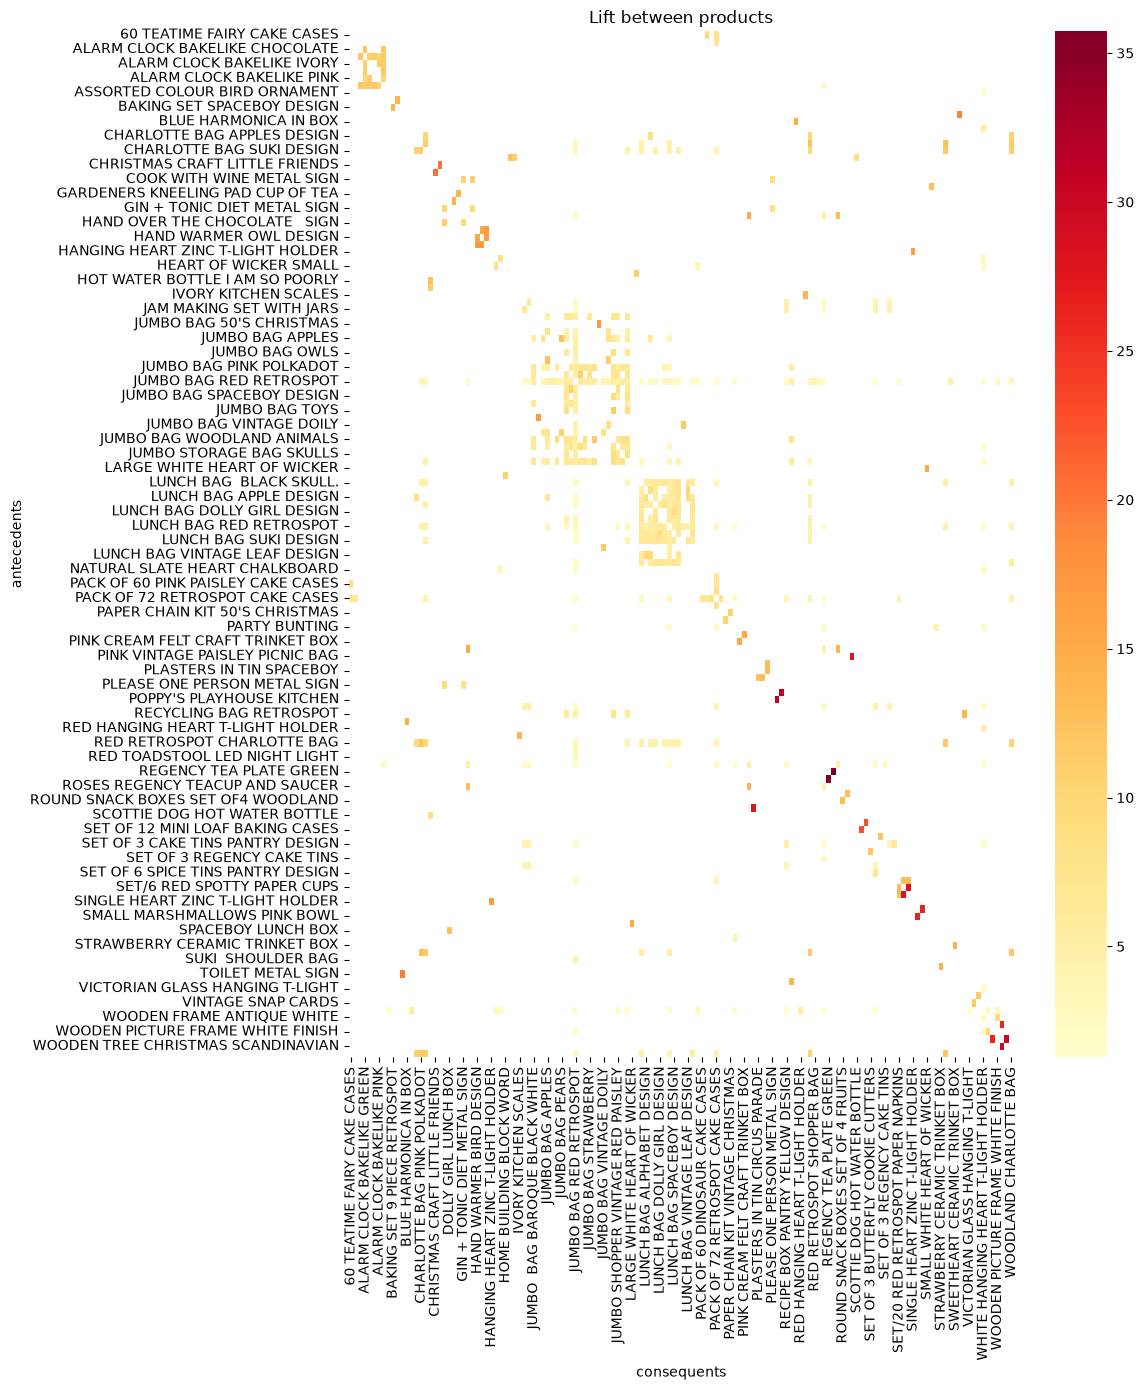

In [161]:
single = rules[~rules["antecedents"].str.contains(",") & ~rules["consequents"].str.contains(",")]
heat = single.pivot_table(index="antecedents", columns="consequents", values="lift")
plt.figure(figsize=(12,14))
sns.heatmap(heat, cmap="YlOrRd")
plt.title("Lift between products")
plt.tight_layout()
plt.show()

In [162]:
print("Baskets:", basket.shape[0], "| Products:", basket.shape[1])
print("Average products per basket:", round(basket.sum(axis=1).mean(), 1))
print("Rules kept:", len(rules))
print("Strongest rule:" ,rules.loc[0,"antecedents"], "->", rules.loc[0,"consequents"], 
      "| lift", round(rules.loc[0, "lift"], 2))

Baskets: 17750 | Products: 2559
Average products per basket: 27.6
Rules kept: 926
Strongest rule: PACK OF 60 PINK PAISLEY CAKE CASES -> 60 TEATIME FAIRY CAKE CASES | lift 9.01


In [163]:
summary = rules[["antecedents", "consequents", "support", "confidence", "lift"]].head(10).round(3)
print(summary)

                          antecedents                         consequents  \
0  PACK OF 60 PINK PAISLEY CAKE CASES         60 TEATIME FAIRY CAKE CASES   
1         60 TEATIME FAIRY CAKE CASES  PACK OF 60 PINK PAISLEY CAKE CASES   
2     PACK OF 72 RETROSPOT CAKE CASES         60 TEATIME FAIRY CAKE CASES   
3         60 TEATIME FAIRY CAKE CASES     PACK OF 72 RETROSPOT CAKE CASES   
4     PACK OF 72 RETROSPOT CAKE CASES      72 SWEETHEART FAIRY CAKE CASES   
5      72 SWEETHEART FAIRY CAKE CASES     PACK OF 72 RETROSPOT CAKE CASES   
6          ALARM CLOCK BAKELIKE GREEN      ALARM CLOCK BAKELIKE CHOCOLATE   
7      ALARM CLOCK BAKELIKE CHOCOLATE          ALARM CLOCK BAKELIKE GREEN   
8            ALARM CLOCK BAKELIKE RED      ALARM CLOCK BAKELIKE CHOCOLATE   
9      ALARM CLOCK BAKELIKE CHOCOLATE            ALARM CLOCK BAKELIKE RED   

   support  confidence    lift  
0    0.019       0.402   9.007  
1    0.019       0.421   9.007  
2    0.024       0.338   7.567  
3    0.024       0.5

In [164]:
summary.to_csv("top10_rules.csv", index=False)

In [165]:
price = clean.groupby("Itemname")["Price"].median()

In [166]:
n = len(basket)
reco = rules[~rules["consequents"].str.contains(",")].copy()
reco["price_b"] = reco["consequents"].map(price)
reco["baskets_with_A"] = reco["antecedent support"] * n
reco["A_without_B"] = reco["baskets_with_A"] * (1 - reco["confidence"])
uptake = 0.05
reco["extra_revenue"] = reco["A_without_B"] * reco["price_b"]

In [167]:
def action(r):
    if r["lift"] >= 3 and r["confidence"] >= 0.5:
        return "Bundle"
    if r["lift"] >= 2:
        return "Cross-sell"
    return "Promotion"

In [168]:
reco["action"] = reco.apply(action, axis=1)
out = reco.sort_values("extra_revenue", ascending=False)[["antecedents", "consequents", "confidence",
 "lift", "action", "extra_revenue"]].head(10).round(2)
print(out)


                            antecedents               consequents  confidence  \
560  WHITE HANGING HEART T-LIGHT HOLDER  REGENCY CAKESTAND 3 TIER        0.16   
302             JUMBO BAG RED RETROSPOT  REGENCY CAKESTAND 3 TIER        0.14   
473             LUNCH BAG RED RETROSPOT  REGENCY CAKESTAND 3 TIER        0.17   
518                       PARTY BUNTING  REGENCY CAKESTAND 3 TIER        0.24   
557    SET OF 3 CAKE TINS PANTRY DESIGN  REGENCY CAKESTAND 3 TIER        0.22   
511     PACK OF 72 RETROSPOT CAKE CASES  REGENCY CAKESTAND 3 TIER        0.27   
136              JAM MAKING SET PRINTED  REGENCY CAKESTAND 3 TIER        0.25   
146            JAM MAKING SET WITH JARS  REGENCY CAKESTAND 3 TIER        0.25   
538     RECIPE BOX PANTRY YELLOW DESIGN  REGENCY CAKESTAND 3 TIER        0.26   
26             ALARM CLOCK BAKELIKE RED  REGENCY CAKESTAND 3 TIER        0.27   

     lift      action  extra_revenue  
560  1.49   Promotion       23319.75  
302  1.28   Promotion       22

## Saving the result to CSV

In [169]:
out.to_csv("recommendations.csv", index=False)